Instalando bibliotecas

In [37]:
%pip install pandas
%pip install ipykernel
%pip install matplotlib
%pip install seaborn
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [39]:
# Importando as bibliotecas necessárias
import os
import pandas as pd

In [40]:
# Definindo o caminho para a pasta de dados
DATA_PATH = os.path.join("..", "data")

In [41]:
# Carregando as 3 bases principais do Olist
orders = pd.read_csv(os.path.join(DATA_PATH, "olist_orders_dataset.csv"))
items = pd.read_csv(os.path.join(DATA_PATH, "olist_order_items_dataset.csv"))
payments = pd.read_csv(os.path.join(DATA_PATH, "olist_order_payments_dataset.csv"))
print("Arquivos carregados com sucesso!")

Arquivos carregados com sucesso!


Explorando a tabela dos pedidos e datas

In [42]:
# 1. Dimensões do DataFrame (quantas linhas e quantas colunas existem)
print("Dimensões da base orders:", orders.shape)

# 2. Exibir as 5 primeiras linhas para entender a estrutura dos dados
orders.head()

Dimensões da base orders: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [43]:
# Contar quantos pedidos existem por cada status de pedido (order_status)
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [44]:
# Informações técnicas sobre as colunas, tipos e valores não nulos
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [45]:
# Lista com o nome de todas as colunas que guardam datas
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

# Convertendo cada uma delas de texto para o formato datetime
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Conferindo se os tipos mudaram
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Explorando a tabela de itens

In [46]:
# 1. Dimensões da base items
print("Dimensões da base items:", items.shape)

# 2. Visualizar as 5 primeiras linhas
items.head()

Dimensões da base items: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [47]:
# 1. Resumo estatístico das colunas numéricas
items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


Unindo as duas tabelas com os pedidos efetivamente entregues

In [48]:
# Cruzamento da tabela de pedidos com a tabela de itens através da chave comum 'order_id'
df_orders_items = pd.merge(
    left=orders, 
    right=items, 
    on='order_id', 
    how='inner'
)

# Verificar as dimensões da nova tabela combinada
print("Dimensões após o cruzamento:", df_orders_items.shape)

# Pré-visualizar as primeiras 3 linhas
df_orders_items.head(3)

Dimensões após o cruzamento: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22


In [49]:
# Filtrando apenas os pedidos que foram efetivamente entregues
df_delivered = df_orders_items[df_orders_items['order_status'] == 'delivered'].copy()

# Verificando a redução do volume
print("Dimensões com pedidos entregues:", df_delivered.shape)

Dimensões com pedidos entregues: (110197, 14)


Visão mensal de compras (Ano-Mês)

In [50]:
# Criar uma coluna no formato 'AAAA-MM' para agrupar as compras por mês
df_delivered['year_month'] = df_delivered['order_purchase_timestamp'].dt.to_period('M')

# Inspecionar as primeiras linhas para confirmar a nova coluna
df_delivered[['order_purchase_timestamp', 'year_month']].head()

,order_purchase_timestamp,year_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


In [51]:
# Agrupamento mensal dos pedidos entregues
monthly_sales = df_delivered.groupby('year_month').agg(
    receita_total=('price', 'sum'),
    total_pedidos=('order_id', 'nunique'),
    total_itens=('order_item_id', 'count')
).reset_index()

# Cálculo do Ticket Médio por pedido
monthly_sales['ticket_medio'] = monthly_sales['receita_total'] / monthly_sales['total_pedidos']

# Visualizar a tabela resultante
monthly_sales

,year_month,receita_total,total_pedidos,total_itens,ticket_medio
0,2016-09,134.97,1,3,134.970000
1,2016-10,40325.11,265,313,152.170226
2,2016-12,10.90,1,1,10.900000
3,2017-01,111798.36,750,913,149.064480
4,2017-02,234223.40,1653,1858,141.695947
5,2017-03,359198.85,2546,2897,141.083602
6,2017-04,340669.68,2303,2569,147.924307
7,2017-05,489338.25,3546,4004,137.997250
8,2017-06,421923.37,3135,3489,134.584807
9,2017-07,481604.52,3872,4416,124.381333


In [52]:
# Filtro temporal: a partir de janeiro de 2017 até agosto de 2018
monthly_growth = monthly_sales[monthly_sales['year_month'] >= '2017-01'].copy()

# Converter a coluna de período para texto para facilitar a visualização nos gráficos
monthly_growth['year_month_str'] = monthly_growth['year_month'].astype(str)

# Visualizar o resumo filtrado
monthly_growth.head()

,year_month,receita_total,total_pedidos,total_itens,ticket_medio,year_month_str
3,2017-01,111798.36,750,913,149.064480,2017-01
4,2017-02,234223.40,1653,1858,141.695947,2017-02
5,2017-03,359198.85,2546,2897,141.083602,2017-03
6,2017-04,340669.68,2303,2569,147.924307,2017-04
7,2017-05,489338.25,3546,4004,137.997250,2017-05


In [53]:
import matplotlib.pyplot as plt

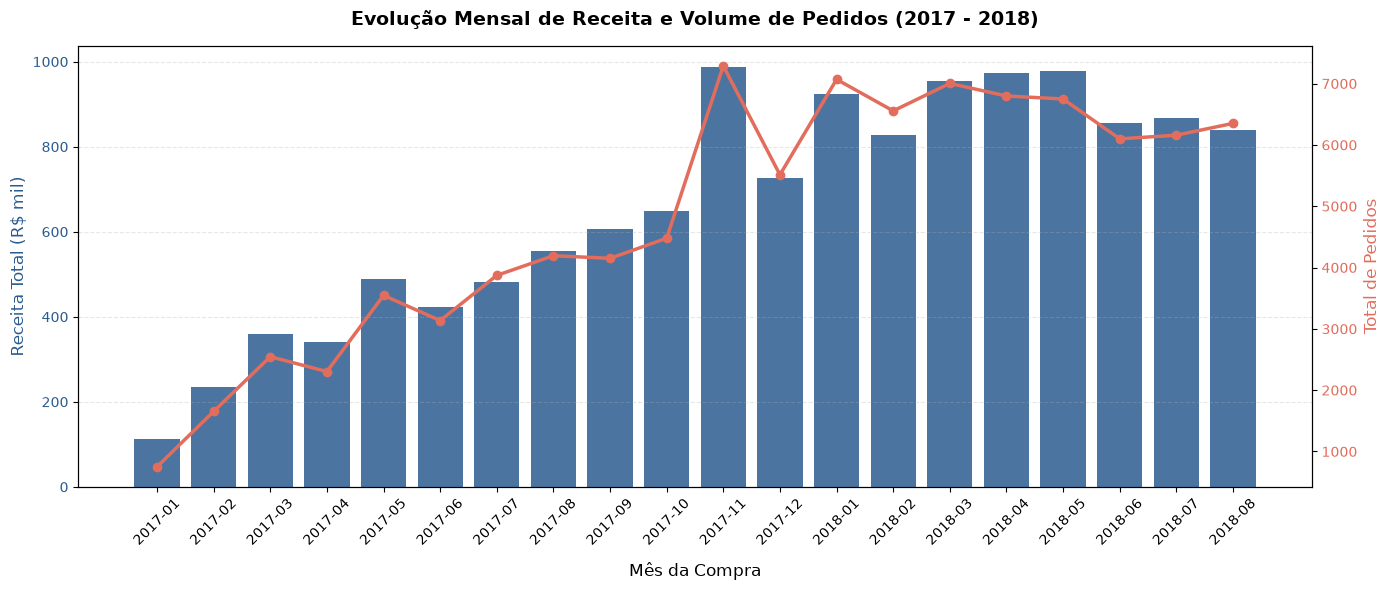

In [54]:
# 1. Configurar tamanho da figura
fig, ax1 = plt.subplots(figsize=(14, 6))

# 2. Plotar a Receita Mensal em Barras (Eixo Y da esquerda)
cor_barras = '#2b5c8f'  # tom de azul sóbrio/executivo
ax1.bar(
    monthly_growth['year_month_str'], 
    monthly_growth['receita_total'] / 1000,  # dividindo por 1.000 para exibir em milhares de R$
    color=cor_barras, 
    alpha=0.85, 
    label='Receita Bruta (em R$ mil)'
)
ax1.set_xlabel('Mês da Compra', fontsize=12, labelpad=10)
ax1.set_ylabel('Receita Total (R$ mil)', fontsize=12, color=cor_barras)
ax1.tick_params(axis='y', labelcolor=cor_barras)
ax1.tick_params(axis='x', rotation=45)

# 3. Criar um segundo eixo vertical (Eixo Y da direita) para o volume de pedidos
ax2 = ax1.twinx()
cor_linha = '#e26d5c'   # tom de coral/terracota para contraste sem poluição visual
ax2.plot(
    monthly_growth['year_month_str'], 
    monthly_growth['total_pedidos'], 
    color=cor_linha, 
    marker='o', 
    linewidth=2.5, 
    label='Qtd. de Pedidos'
)
ax2.set_ylabel('Total de Pedidos', fontsize=12, color=cor_linha)
ax2.tick_params(axis='y', labelcolor=cor_linha)

# 4. Ajustes de estética executiva
plt.title('Evolução Mensal de Receita e Volume de Pedidos (2017 - 2018)', fontsize=14, pad=15, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Exibir gráfico limpo
plt.tight_layout()
plt.show()

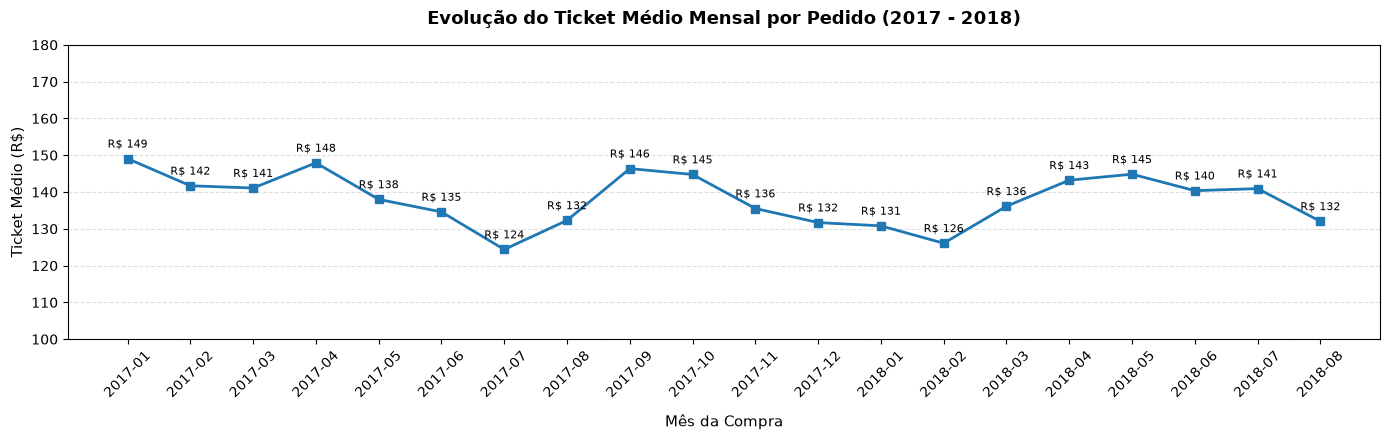

In [55]:
# Gráfico de evolução do Ticket Médio mensal (com 2 casas decimais)
plt.figure(figsize=(14, 4.5))

plt.plot(
    monthly_growth['year_month_str'], 
    monthly_growth['ticket_medio'], 
    marker='s', 
    color='#1f77b4', 
    linewidth=2, 
    markersize=6
)

# Ajustes de visualização
plt.title('Evolução do Ticket Médio Mensal por Pedido (2017 - 2018)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Mês da Compra', fontsize=11, labelpad=10)
plt.ylabel('Ticket Médio (R$)', fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Definir limites no eixo Y para manter a escala visual proporcional
plt.ylim(100, 180)

# Inserir o valor exato com 2 casas decimais acima de cada ponto
for i, row in monthly_growth.iterrows():
    valor_formatado = f"R$ {row['ticket_medio']:.0f}"
    plt.annotate(
        valor_formatado,
        (row['year_month_str'], row['ticket_medio']),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [56]:
# Carregando as bases de produtos e clientes
products = pd.read_csv(os.path.join(DATA_PATH, "olist_products_dataset.csv"))
customers = pd.read_csv(os.path.join(DATA_PATH, "olist_customers_dataset.csv"))

print("Tabelas de produtos e clientes carregadas com sucesso!")
print(f"Produtos: {products.shape}")
print(f"Clientes: {customers.shape}")

Tabelas de produtos e clientes carregadas com sucesso!
Produtos: (32951, 9)
Clientes: (99441, 5)


In [57]:
# 1. Cruzar com a tabela de produtos para trazer a categoria
# Selecionamos apenas as colunas que realmente precisamos para não pesar a memória
df_delivered = pd.merge(
    df_delivered,
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

# 2. Cruzar com a tabela de clientes para trazer o estado (UF) do comprador
df_delivered = pd.merge(
    df_delivered,
    customers[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)

# Verificar se as novas colunas foram adicionadas com sucesso
print("Novas dimensões da base:", df_delivered.shape)
df_delivered[['order_id', 'product_category_name', 'customer_state', 'price']].head()

Novas dimensões da base: (110197, 17)


,order_id,product_category_name,customer_state,price
0,e481f51cbdc54678b7cc49136f2d6af7,utilidades_domesticas,SP,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,perfumaria,BA,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,automotivo,GO,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,pet_shop,RN,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,papelaria,SP,19.90


In [58]:
# 1. Agrupamento por categoria e cálculo do faturamento total
cat_sales = df_delivered.groupby('product_category_name')['price'].sum().reset_index()
cat_sales.columns = ['categoria', 'receita_total']

# 2. Ordenar do maior para o menor faturamento
cat_sales = cat_sales.sort_values(by='receita_total', ascending=False)

# 3. Percentual individual de cada categoria
cat_sales['percentual'] = (cat_sales['receita_total'] / cat_sales['receita_total'].sum()) * 100

# 4. Percentual acumulado (soma cumulativa dos percentuais)
cat_sales['percentual_acumulado'] = cat_sales['percentual'].cumsum()

# 5. Exibir as 10 principais categorias
top_10_cat = cat_sales.head(10).copy()
top_10_cat

,categoria,receita_total,percentual,percentual_acumulado
11,beleza_saude,1233131.72,9.448727,9.448727
66,relogios_presentes,1166176.98,8.935694,18.384420
13,cama_mesa_banho,1023434.76,7.841948,26.226369
32,esporte_lazer,954852.55,7.316445,33.542814
44,informatica_acessorios,888724.61,6.809748,40.352562
54,moveis_decoracao,711927.69,5.455062,45.807624
72,utilidades_domesticas,615628.69,4.717182,50.524806
26,cool_stuff,610204.10,4.675617,55.200423
8,automotivo,578966.65,4.436264,59.636687
12,brinquedos,471286.48,3.611177,63.247864


In [59]:
# 1. Agrupamento por estado do comprador
state_sales = df_delivered.groupby('customer_state')['price'].sum().reset_index()
state_sales.columns = ['estado', 'receita_total']

# 2. Ordenar do maior para o menor
state_sales = state_sales.sort_values(by='receita_total', ascending=False)

# 3. Percentual individual
state_sales['percentual'] = (state_sales['receita_total'] / state_sales['receita_total'].sum()) * 100

# 4. Percentual acumulado
state_sales['percentual_acumulado'] = state_sales['percentual'].cumsum()

# 5. Exibir os 5 principais estados
top_5_states = state_sales.head(5).copy()
top_5_states

,estado,receita_total,percentual,percentual_acumulado
25,SP,5067633.16,38.328736,38.328736
18,RJ,1759651.13,13.309015,51.637751
10,MG,1552481.83,11.742102,63.379853
22,RS,728897.47,5.512972,68.892825
17,PR,666063.51,5.037731,73.930556


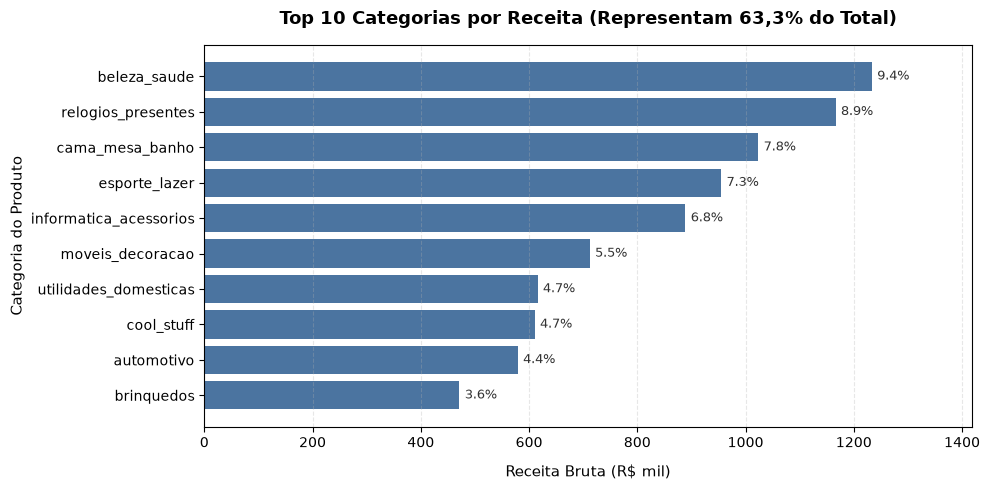

In [60]:
import matplotlib.pyplot as plt

# 1. Configurar área do gráfico
plt.figure(figsize=(10, 5))

# 2. Plotar barras horizontais (invertendo a ordem para o maior ficar no topo)
top_10_grafico = top_10_cat.sort_values(by='receita_total', ascending=True)

barras = plt.barh(
    top_10_grafico['categoria'], 
    top_10_grafico['receita_total'] / 1000, 
    color='#2b5c8f', 
    alpha=0.85
)

# 3. Adicionar o percentual de cada categoria no final de cada barra
for barra, pct in zip(barras, top_10_grafico['percentual']):
    plt.text(
        barra.get_width() + 10, 
        barra.get_y() + barra.get_height() / 2, 
        f"{pct:.1f}%", 
        va='center', 
        fontsize=9, 
        color='#333333'
    )

# 4. Ajustes executivos
plt.title('Top 10 Categorias por Receita (Representam 63,3% do Total)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Receita Bruta (R$ mil)', fontsize=11, labelpad=10)
plt.ylabel('Categoria do Produto', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.xlim(0, top_10_grafico['receita_total'].max() / 1000 * 1.15)  # margem para o texto caber

plt.tight_layout()
plt.show()

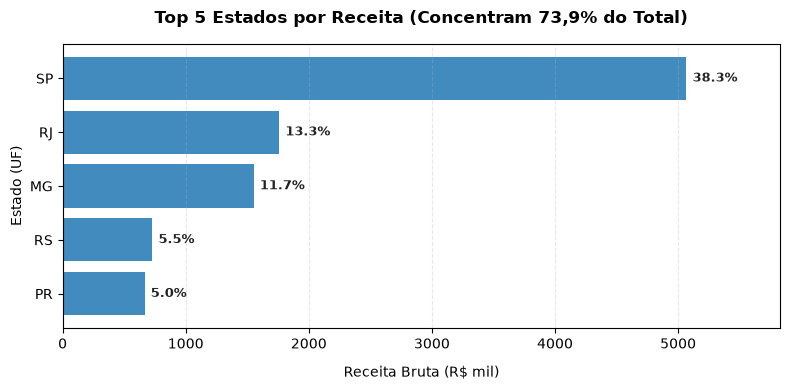

In [61]:
# 1. Configurar área do gráfico
plt.figure(figsize=(8, 4))

# 2. Ordenar para o maior estado ficar no topo
top_5_grafico = top_5_states.sort_values(by='receita_total', ascending=True)

barras_est = plt.barh(
    top_5_grafico['estado'], 
    top_5_grafico['receita_total'] / 1000, 
    color='#1f77b4', 
    alpha=0.85
)

# 3. Adicionar o percentual ao lado de cada barra
for barra, pct in zip(barras_est, top_5_grafico['percentual']):
    plt.text(
        barra.get_width() + 50, 
        barra.get_y() + barra.get_height() / 2, 
        f"{pct:.1f}%", 
        va='center', 
        fontsize=9, 
        fontweight='bold',
        color='#222222'
    )

# 4. Ajustes executivos
plt.title('Top 5 Estados por Receita (Concentram 73,9% do Total)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Receita Bruta (R$ mil)', fontsize=10, labelpad=10)
plt.ylabel('Estado (UF)', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.xlim(0, top_5_grafico['receita_total'].max() / 1000 * 1.15)

plt.tight_layout()
plt.show()

In [62]:
# 1. Calcular o tempo real de entrega (em dias corridos)
# Subtraímos as datas e dividimos por timedelta de 1 dia para obter o número em dias decimais
df_delivered['dias_entrega_real'] = (
    df_delivered['order_delivered_customer_date'] - df_delivered['order_purchase_timestamp']
).dt.total_seconds() / 86400  # 86.400 segundos = 1 dia

# 2. Calcular a diferença entre a data estimada e a data real de entrega
# Se o resultado for negativo, significa que a entrega foi realizada APÓS a data estimada (atraso)
df_delivered['diferenca_estimada_dias'] = (
    df_delivered['order_estimated_delivery_date'] - df_delivered['order_delivered_customer_date']
).dt.total_seconds() / 86400

# 3. Criar uma coluna booleana (True/False) indicando se houve atraso
df_delivered['foi_atrasado'] = df_delivered['diferenca_estimada_dias'] < 0

# 4. Resumo estatístico do tempo real de entrega
print("--- Estatísticas do Tempo Real de Entrega (dias) ---")
print(df_delivered['dias_entrega_real'].describe())

# 5. Taxa de cumprimento de prazo (SLA)
total_pedidos_logistica = len(df_delivered)
pedidos_no_prazo = (df_delivered['foi_atrasado'] == False).sum()
pedidos_atrasados = df_delivered['foi_atrasado'].sum()

print("\n--- Cumprimento de Prazo (SLA) ---")
print(f"Entregues no Prazo: {pedidos_no_prazo:,} ({pedidos_no_prazo / total_pedidos_logistica * 100:.2f}%)")
print(f"Entregues com Atraso: {pedidos_atrasados:,} ({pedidos_atrasados / total_pedidos_logistica * 100:.2f}%)")

--- Estatísticas do Tempo Real de Entrega (dias) ---
count    110189.000000
mean         12.472246
std           9.445346
min           0.533414
25%           6.736192
50%          10.184201
75%          15.540810
max         209.628611
Name: dias_entrega_real, dtype: float64

--- Cumprimento de Prazo (SLA) ---
Entregues no Prazo: 101,483 (92.09%)
Entregues com Atraso: 8,714 (7.91%)


In [63]:
# 1. Agrupar por estado para avaliar métricas logísticas
logistica_estados = df_delivered.groupby('customer_state').agg(
    total_pedidos=('order_id', 'nunique'),
    prazo_medio_dias=('dias_entrega_real', 'mean'),
    prazo_mediano_dias=('dias_entrega_real', 'median'),
    taxa_atraso_pct=('foi_atrasado', lambda x: x.mean() * 100),
    frete_medio=('freight_value', 'mean')
).reset_index()

# 2. Filtrar estados com volume estatisticamente representativo (ex: mais de 100 pedidos)
logistica_estados = logistica_estados[logistica_estados['total_pedidos'] >= 100]

# 3. Ordenar pelos estados com MAIOR taxa de atraso
top_atrasos = logistica_estados.sort_values(by='taxa_atraso_pct', ascending=False).head(5)

# 4. Ordenar pelos estados com MENOR tempo de entrega (mais rápidos)
top_rapidos = logistica_estados.sort_values(by='prazo_mediano_dias', ascending=True).head(5)

print("--- Top 5 Estados com MAIOR Taxa de Atraso ---")
print(top_atrasos[['customer_state', 'total_pedidos', 'taxa_atraso_pct', 'prazo_mediano_dias', 'frete_medio']])

print("\n--- Top 5 Estados MAIS RÁPIDOS (Menor Prazo Mediano) ---")
print(top_rapidos[['customer_state', 'total_pedidos', 'prazo_mediano_dias', 'taxa_atraso_pct', 'frete_medio']])

--- Top 5 Estados com MAIOR Taxa de Atraso ---
   customer_state  total_pedidos  taxa_atraso_pct  prazo_mediano_dias  \
1              AL            397        24.121780           22.066007   
9              MA            717        20.375000           19.319907   
24             SE            335        16.266667           17.957245   
16             PI            476        15.487572           16.335486   
5              CE           1279        15.287518           18.088241   

    frete_medio  
1     35.870656  
9     38.492712  
24    36.573173  
16    39.115086  
5     32.734495  

--- Top 5 Estados MAIS RÁPIDOS (Menor Prazo Mediano) ---
   customer_state  total_pedidos  prazo_mediano_dias  taxa_atraso_pct  \
25             SP          40501            7.206898         5.767740   
10             MG          11354           10.322703         5.442862   
17             PR           4923           10.361007         4.779607   
6              DF           2080           11.259896    

In [64]:
# 1. Carregar a base de avaliações dos clientes
reviews = pd.read_csv(os.path.join(DATA_PATH, "olist_order_reviews_dataset.csv"))
print("Dimensões da tabela reviews:", reviews.shape)

# 2. Selecionar apenas as colunas essenciais: identificador do pedido e nota dada (1 a 5)
reviews_subset = reviews[['order_id', 'review_score']].copy()

# Como um pedido pode raramente ter mais de uma avaliação registrada,
# pegamos a média por pedido para garantir 1 linha por order_id
reviews_por_pedido = reviews_subset.groupby('order_id')['review_score'].mean().reset_index()

# 3. Cruzar com a nossa base analítica (df_delivered)
df_delivered = pd.merge(
    df_delivered,
    reviews_por_pedido,
    on='order_id',
    how='left'
)

# 4. Comparar a nota média de acordo com o cumprimento do prazo
comparativo_satisfacao = df_delivered.groupby('foi_atrasado').agg(
    total_pedidos=('order_id', 'nunique'),
    score_medio=('review_score', 'mean'),
    score_mediano=('review_score', 'median')
).reset_index()

# Renomear os rótulos de True/False para nomes executivos
comparativo_satisfacao['status_entrega'] = comparativo_satisfacao['foi_atrasado'].map({
    False: 'Entregue no Prazo',
    True: 'Entregue com Atraso'
})

print("\n--- Impacto do Atraso na Nota de Avaliação (1 a 5) ---")
print(comparativo_satisfacao[['status_entrega', 'total_pedidos', 'score_medio', 'score_mediano']])

Dimensões da tabela reviews: (99224, 7)

--- Impacto do Atraso na Nota de Avaliação (1 a 5) ---
        status_entrega  total_pedidos  score_medio  score_mediano
0    Entregue no Prazo          88652     4.211551            5.0
1  Entregue com Atraso           7826     2.548891            2.0


In [65]:
# 1. Criar a coluna com a nota arredondada para número inteiro
df_delivered['review_score_int'] = df_delivered['review_score'].round().astype('Int64')

# 2. Gerar a tabela cruzada percentual (normalizada por linha)
distribuicao_notas = pd.crosstab(
    df_delivered['foi_atrasado'],
    df_delivered['review_score_int'],
    normalize='index'
) * 100

# 3. Ajustar os rótulos das linhas e das colunas para apresentação executiva
distribuicao_notas.index = ['No Prazo', 'Com Atraso']
distribuicao_notas.columns = [f"Nota {col}" for col in distribuicao_notas.columns]

# 4. Exibir a tabela formatada com 1 casa decimal
distribuicao_notas.round(1)

,Nota 1,Nota 2,Nota 3,Nota 4,Nota 5
No Prazo,8.4,3.0,8.2,19.9,60.5
Com Atraso,46.9,7.8,11.1,12.1,22.2


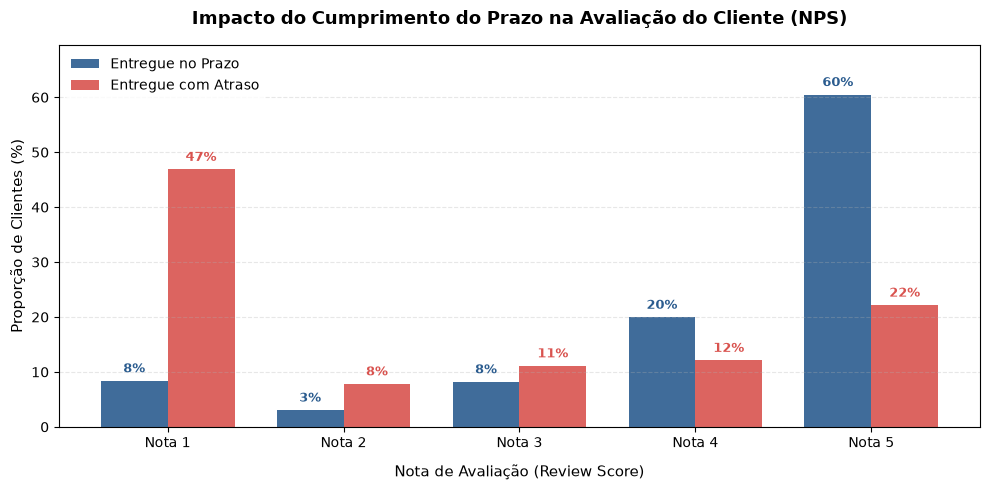

In [66]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Arredondar o review_score para números inteiros (1, 2, 3, 4, 5)
df_delivered['review_score_int'] = df_delivered['review_score'].round()

# 2. Recriar a tabela percentual apenas para as notas válidas de 1 a 5
dist_grafico = pd.crosstab(
    df_delivered['foi_atrasado'],
    df_delivered['review_score_int'],
    normalize='index'
) * 100

# 3. Garantir explicitamente as 5 notas no eixo
notas = [1, 2, 3, 4, 5]
pct_no_prazo = [dist_grafico.loc[False, n] if n in dist_grafico.columns else 0 for n in notas]
pct_com_atraso = [dist_grafico.loc[True, n] if n in dist_grafico.columns else 0 for n in notas]

# 4. Configurar posições no eixo X
x = np.arange(len(notas))
largura = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

cor_prazo = '#2b5c8f'
cor_atraso = '#d9534f'

# 5. Plotar as barras emparelhadas
barras1 = ax.bar(x - largura / 2, pct_no_prazo, largura, label='Entregue no Prazo', color=cor_prazo, alpha=0.9)
barras2 = ax.bar(x + largura / 2, pct_com_atraso, largura, label='Entregue com Atraso', color=cor_atraso, alpha=0.9)

# 6. Rótulos percentuais inteiros sobre cada barra
for barra in barras1:
    h = barra.get_height()
    ax.annotate(f"{h:.0f}%",
                xy=(barra.get_x() + barra.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=cor_prazo)

for barra in barras2:
    h = barra.get_height()
    ax.annotate(f"{h:.0f}%",
                xy=(barra.get_x() + barra.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=cor_atraso)

# 7. Estética executiva
ax.set_title('Impacto do Cumprimento do Prazo na Avaliação do Cliente (NPS)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Nota de Avaliação (Review Score)', fontsize=11, labelpad=10)
ax.set_ylabel('Proporção de Clientes (%)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels([f"Nota {n}" for n in notas], fontsize=10)
ax.set_ylim(0, max(max(pct_no_prazo), max(pct_com_atraso)) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=10)

plt.tight_layout()
plt.show()

In [67]:
# 1. Carregar a base de pagamentos
payments = pd.read_csv(os.path.join(DATA_PATH, "olist_order_payments_dataset.csv"))

# 2. Inspecionar dimensões e primeiras linhas
print("Dimensões da base payments:", payments.shape)
payments.head()

Dimensões da base payments: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [68]:
# 1. Cruzar a base de pagamentos com as encomendas válidas (df_delivered)
# Mantemos apenas os pagamentos correspondentes às encomendas entregues que já tratámos
df_payments = pd.merge(
    df_delivered[['order_id']].drop_duplicates(),
    payments,
    on='order_id',
    how='inner'
)

# 2. Agrupar por tipo de pagamento e calcular métricas financeiras
resumo_pagamentos = df_payments.groupby('payment_type').agg(
    total_transacoes=('order_id', 'count'),
    pedidos_unicos=('order_id', 'nunique'),
    receita_total=('payment_value', 'sum'),
    ticket_medio=('payment_value', 'mean')
).reset_index()

# 3. Calcular percentuais de representatividade
resumo_pagamentos['pct_pedidos'] = (
    resumo_pagamentos['pedidos_unicos'] / resumo_pagamentos['pedidos_unicos'].sum()
) * 100

resumo_pagamentos['pct_receita'] = (
    resumo_pagamentos['receita_total'] / resumo_pagamentos['receita_total'].sum()
) * 100

# 4. Ordenar do maior para o menor faturamento
resumo_pagamentos = resumo_pagamentos.sort_values(by='receita_total', ascending=False)

# 5. Formatar a visualização tabular para leitura executiva
resumo_pagamentos_formatado = resumo_pagamentos.copy()
resumo_pagamentos_formatado['receita_total'] = resumo_pagamentos_formatado['receita_total'].map('R$ {:,.2f}'.format)
resumo_pagamentos_formatado['ticket_medio'] = resumo_pagamentos_formatado['ticket_medio'].map('R$ {:,.2f}'.format)
resumo_pagamentos_formatado['pct_pedidos'] = resumo_pagamentos_formatado['pct_pedidos'].map('{:.1f}%'.format)
resumo_pagamentos_formatado['pct_receita'] = resumo_pagamentos_formatado['pct_receita'].map('{:.1f}%'.format)

resumo_pagamentos_formatado

,payment_type,total_transacoes,pedidos_unicos,receita_total,ticket_medio,pct_pedidos,pct_receita
1,credit_card,74586,74304,"R$ 12,101,094.88",R$ 162.24,75.3%,78.5%
0,boleto,19191,19191,"R$ 2,769,932.58",R$ 144.33,19.5%,18.0%
3,voucher,5493,3679,"R$ 343,013.19",R$ 62.45,3.7%,2.2%
2,debit_card,1486,1485,"R$ 208,421.12",R$ 140.26,1.5%,1.4%


In [69]:
# 0. Criar o subset de pagamentos via cartão de crédito a partir de df_payments
df_cartao = df_payments[df_payments['payment_type'] == 'credit_card'].copy()

# 1. Corrigir as 2 ocorrências com parcela 0 imputando 1 (à vista)
df_cartao.loc[df_cartao['payment_installments'] == 0, 'payment_installments'] = 1

# 2. Recalcular o agrupamento por número de parcelas
parcelas_resumo = df_cartao.groupby('payment_installments').agg(
    total_pedidos=('order_id', 'nunique'),
    receita_total=('payment_value', 'sum'),
    ticket_medio=('payment_value', 'mean')
).reset_index()

# 3. Calcular percentuais sobre o total do cartão de crédito
parcelas_resumo['pct_pedidos'] = (
    parcelas_resumo['total_pedidos'] / parcelas_resumo['total_pedidos'].sum()
) * 100

parcelas_resumo['pct_receita'] = (
    parcelas_resumo['receita_total'] / parcelas_resumo['receita_total'].sum()
) * 100

# 4. Formatar para exibição limpa (primeiras 10 parcelas)
parcelas_formatado = parcelas_resumo.head(10).copy()
parcelas_formatado['receita_total'] = parcelas_formatado['receita_total'].map('R$ {:,.2f}'.format)
parcelas_formatado['ticket_medio'] = parcelas_formatado['ticket_medio'].map('R$ {:,.2f}'.format)
parcelas_formatado['pct_pedidos'] = parcelas_formatado['pct_pedidos'].map('{:.1f}%'.format)
parcelas_formatado['pct_receita'] = parcelas_formatado['pct_receita'].map('{:.1f}%'.format)

# 5. Exibir a tabela na tela
parcelas_formatado

,payment_installments,total_pedidos,receita_total,ticket_medio,pct_pedidos,pct_receita
0,1,24713,"R$ 2,367,149.36",R$ 95.60,33.2%,19.6%
1,2,12052,"R$ 1,528,581.69",R$ 126.59,16.2%,12.6%
2,3,10147,"R$ 1,443,288.05",R$ 142.00,13.6%,11.9%
3,4,6882,"R$ 1,127,647.37",R$ 163.64,9.2%,9.3%
4,5,5090,"R$ 928,837.73",R$ 182.30,6.8%,7.7%
5,6,3800,"R$ 793,288.80",R$ 208.54,5.1%,6.6%
6,7,1560,"R$ 290,643.18",R$ 185.95,2.1%,2.4%
7,8,4122,"R$ 1,266,801.58",R$ 306.29,5.5%,10.5%
8,9,618,"R$ 122,346.20",R$ 197.97,0.8%,1.0%
9,10,5137,"R$ 2,114,267.90",R$ 410.54,6.9%,17.5%


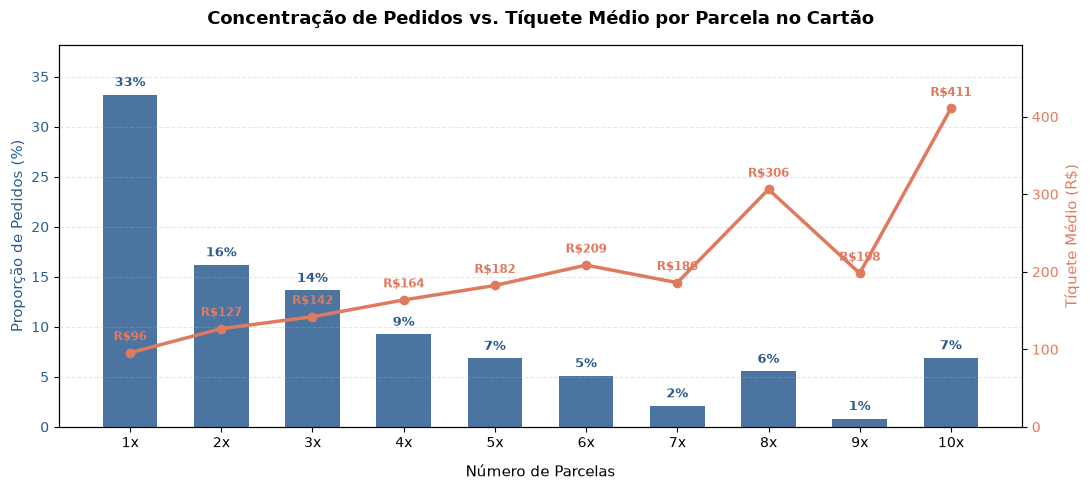

In [70]:
import matplotlib.pyplot as plt

# 1. Isolar as parcelas de 1 a 10 (onde se concentra a imensa maioria)
dados_grafico = parcelas_resumo.head(10).copy()

# 2. Configurar a figura e o primeiro eixo (Barras - Percentual de Pedidos)
fig, ax1 = plt.subplots(figsize=(11, 5))

cor_barras = '#2b5c8f'
cor_linha = '#e07a5f'

barras = ax1.bar(
    dados_grafico['payment_installments'],
    dados_grafico['pct_pedidos'],
    color=cor_barras,
    alpha=0.85,
    width=0.6,
    label='% de Pedidos'
)

# Rótulos percentuais inteiros sobre as barras
for barra in barras:
    altura = barra.get_height()
    ax1.annotate(
        f"{altura:.0f}%",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=cor_barras
    )

ax1.set_xlabel('Número de Parcelas', fontsize=11, labelpad=10)
ax1.set_ylabel('Proporção de Pedidos (%)', fontsize=11, color=cor_barras)
ax1.tick_params(axis='y', labelcolor=cor_barras)
ax1.set_xticks(dados_grafico['payment_installments'])
ax1.set_xticklabels([f"{int(p)}x" for p in dados_grafico['payment_installments']], fontsize=10)
ax1.set_ylim(0, dados_grafico['pct_pedidos'].max() * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# 3. Criar o segundo eixo Y (Linha - Tíquete Médio)
ax2 = ax1.twinx()
linha = ax2.plot(
    dados_grafico['payment_installments'],
    dados_grafico['ticket_medio'],
    color=cor_linha,
    marker='o',
    linewidth=2.5,
    markersize=6,
    label='Tíquete Médio (R$)'
)

# Rótulos de valor monetário acima dos pontos da linha
for _, row in dados_grafico.iterrows():
    ax2.annotate(
        f"R${row['ticket_medio']:.0f}",
        xy=(row['payment_installments'], row['ticket_medio']),
        xytext=(0, 7),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=8.5,
        fontweight='bold',
        color=cor_linha
    )

ax2.set_ylabel('Tíquete Médio (R$)', fontsize=11, color=cor_linha)
ax2.tick_params(axis='y', labelcolor=cor_linha)
ax2.set_ylim(0, dados_grafico['ticket_medio'].max() * 1.2)

# 4. Título executivo
plt.title('Concentração de Pedidos vs. Tíquete Médio por Parcela no Cartão', fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()